In [2]:
import numpy as np
import astropy
from astropy.io import fits
import sep
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import Arrow,Ellipse

ModuleNotFoundError: No module named 'sep'

In [25]:
%matplotlib inline  
rcParams['figure.figsize'] = [10.,8.]
rcParams['ytick.direction'] = 'in'
rcParams['xtick.direction'] = 'in'

In [26]:
data_fname = 'hlsp_hudf12_hst_wfc3ir_udfmain_f105w_v1.0_drz.fits'
data_name = 'f105'
data = fits.getdata(data_fname)
data = np.astype(data,np.float32)

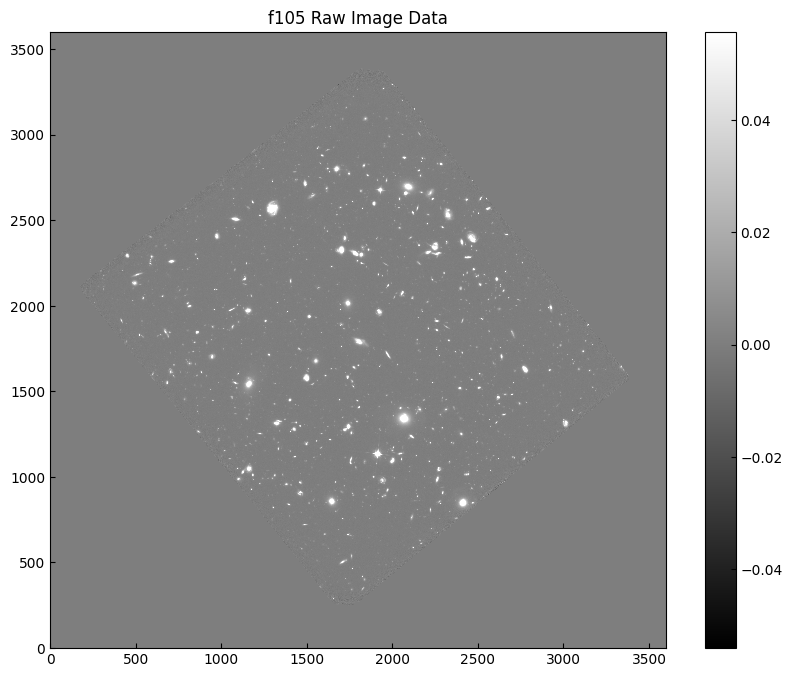

In [27]:
m, s = np.mean(data), np.std(data)
plt.imshow(data, interpolation='nearest',cmap='grey',vmin=m-s,vmax=m+s,origin='lower')
plt.title(f'{data_name} Raw Image Data')
_ = plt.colorbar()
plt.savefig('Final_{}_raw.png'.format(data_name),bbox_inches='tight',dpi = 600)

Characterizing the background and noise values.


In [28]:
bkg = sep.Background(data)
print(f'{bkg.globalback = }')
print(f'{bkg.globalrms = }')
bkg_image = bkg.back()

bkg.globalback = 0.0
bkg.globalrms = 0.0005398219218477607


Showing and saving plot of the background data.

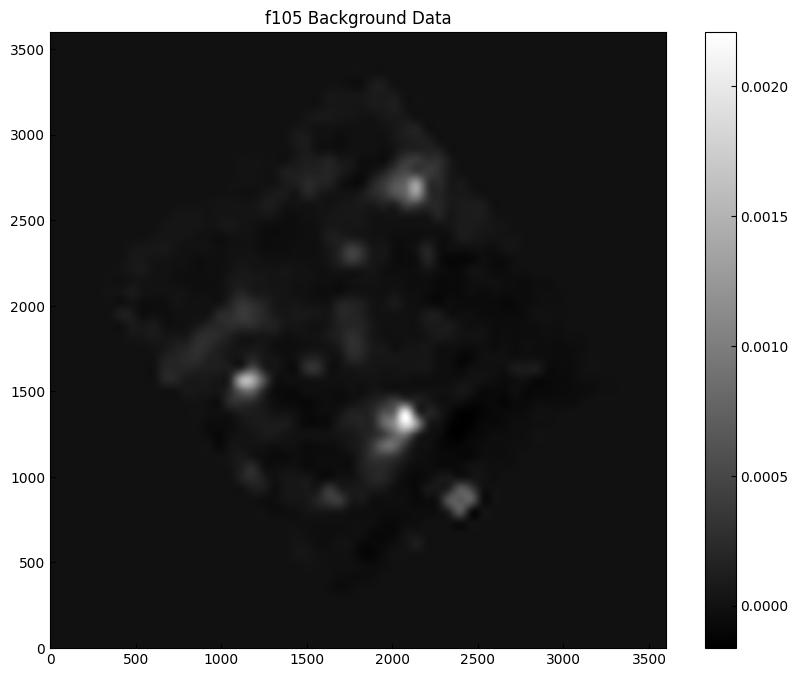

In [29]:
plt.imshow(bkg_image, interpolation='nearest', cmap='gray', origin='lower')
plt.title(f'{data_name} Background Data')
_ = plt.colorbar()
plt.savefig('Final_{}_background.png'.format(data_name),bbox_inches='tight',dpi = 600)

Evaluating the background noise as 2-d `numpy` array, same size as original image.


In [30]:
bkg_rms = bkg.rms()

Showing and saving the background noise data.

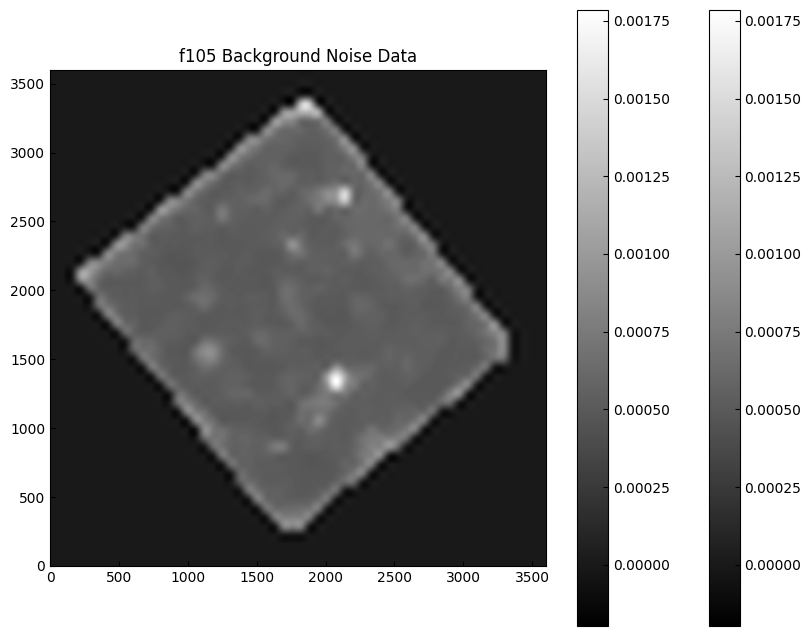

In [31]:
plt.imshow(bkg_rms, interpolation='nearest', cmap='gray', origin='lower')
plt.title(f'{data_name} Background Noise Data')
plt.colorbar()
_ = plt.colorbar()
plt.savefig('Final_{}_noise.png'.format(data_name),bbox_inches='tight',dpi = 600)


Subtracting the background data and noise from the origin image data. This facilitates the image extraction and avoids    accidentally extracting patches of noise as though they were objects. 

In [32]:
data_sub = data - bkg

Using the background-subtracted image data in a call to `sep`'s `extract` function. The threshold is set at 1.5*sigma and will be dynamically adjust on a per-pixel basis with the noise values stored in `bkg.globalrms`. The object data is stored in a structered `numpy` array.

In [33]:
objects = sep.extract(data_sub, 1.5, err=bkg.globalrms)

Getting a quick count of how many objects were detected.

In [34]:
object_count = len(objects)
print(f'Found {object_count} objects.')

Found 8630 objects.


Plotting the background-subtracted image data in the same way as the raw data, then iterating through each object and uses the stored values for: the x and y position, the orthogonal major and minor axes of the object's enclosing ellipse, and the angle to which those axes are rotated from the standard i,j basis
to plot ellipses on the image where the detected object lie. 

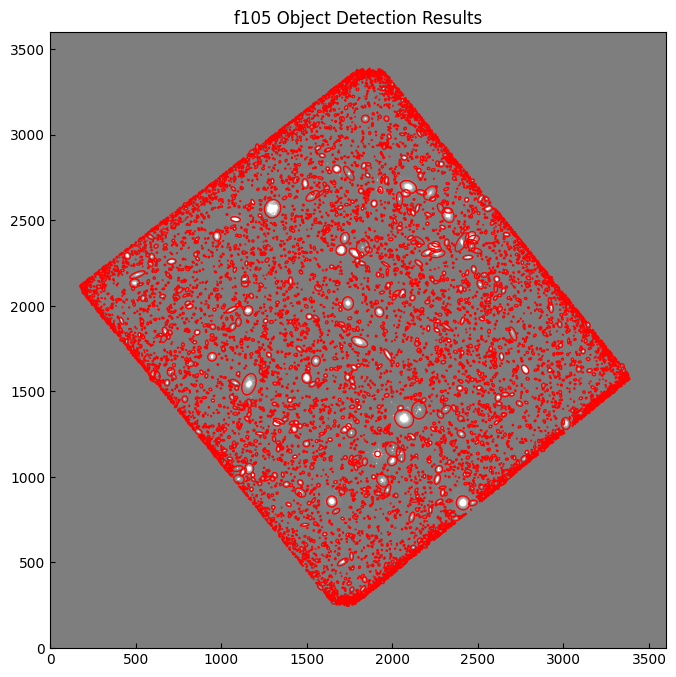

In [35]:
# plot background-subtracted image
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
im = ax.imshow(data_sub, interpolation='nearest', cmap='gray',
               vmin=m-s, vmax=m+s, origin='lower')

ax.set_title(f'{data_name} Object Detection Results')

# plot an ellipse for each object
for i in range(len(objects)):
    e = Ellipse(xy=(objects['x'][i], objects['y'][i]),
                width=6*objects['a'][i],
                height=6*objects['b'][i],
                angle=objects['theta'][i] * 180. / np.pi)
    e.set_facecolor('none')
    e.set_edgecolor('red')
    ax.add_artist(e)

plt.savefig('Final_{}_detection.png'.format(data_name),bbox_inches='tight',dpi = 600)

### Flux Values
Computes the brightness of each of the detected objects using simple circular photometry. Instead of defining an outer annulus to get the background/noise value to subtract, uses the background object's global value. 

In [36]:
flux, fluxerr, flag = sep.sum_circle(data_sub, objects['x'], objects['y'],
                                     3.0, err=bkg.globalrms, gain=1.0)

### Inspecting Fluxes of Detected Objects

Shows the calculated flux and error for the first ten objects.  
Plots histograms of flux and log10(flux) values for f105.  

The histogram of the flux values shows that there are a majority of values near zero. This is expected as there are large swaths of black surround what appears to be a rotated data rich area. 

object 0: flux = 0.031282 +/- 0.176890
object 1: flux = 0.031018 +/- 0.176142
object 2: flux = -0.024388 +/- 0.002883
object 3: flux = 0.001947 +/- 0.044219
object 4: flux = 0.012457 +/- 0.111649
object 5: flux = -0.011228 +/- 0.002875
object 6: flux = 0.029368 +/- 0.171394
object 7: flux = -0.009126 +/- 0.002875
object 8: flux = 0.048023 +/- 0.219161
object 9: flux = 0.027840 +/- 0.166877


C:\Users\zacha\AppData\Local\Temp\ipykernel_13492\3640724756.py:4: RuntimeWarning: invalid value encountered in log10
  flux_log = np.log10(flux)


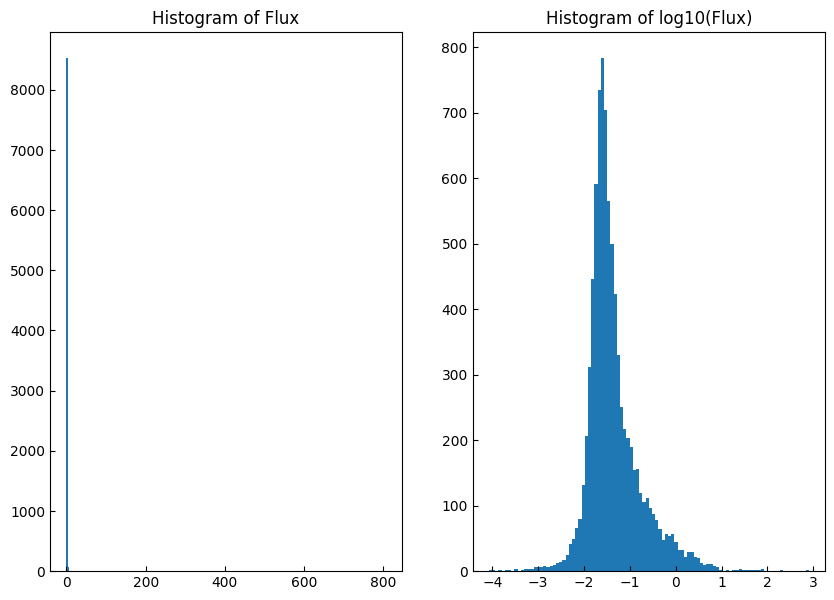

In [43]:
for i in range(10):
    print("object {:d}: flux = {:f} +/- {:f}".format(i, flux[i], fluxerr[i]))

flux_log = np.log10(flux)

f,ax = plt.subplots(1,2,figsize = (10,7))
_ =ax[0].hist(flux,bins=200)
_ = ax[0].set_title('Histogram of Flux')
_ =ax[1].hist(flux_log,bins=100)
_ = ax[1].set_title('Histogram of log10(Flux)')

### Locating and Characterizing the Largest Outlier 

In [38]:
f105_flux_mean = np.mean(flux)
f105_flux_median = np.median(flux)
f105_flux_std = np.std(flux)


f105_flux_shifted = flux-f105_flux_mean
f105_flux_shifted = np.abs(f105_flux_shifted)
f105_largest_outlier_shifted = max(f105_flux_shifted)

for i,val in enumerate(f105_flux_shifted):
    if val == f105_largest_outlier_shifted:
        f105_largest_outlier = flux[i]
        f105_largest_outlier_index = i
f105_largest_outlier_sigma = f105_largest_outlier_shifted/f105_flux_std

print(f'{data_name} Mean: {f105_flux_mean:f}\n{data_name} Median: {f105_flux_median:f}\n{data_name} Standard deviation: {f105_flux_std:f}')
print(f'Largest Outlier:\n  Object: {f105_largest_outlier_index}', 
      f'Flux: {f105_largest_outlier:f}',
      f'Sigma: {f105_largest_outlier_sigma:f} \u03c3',
      sep='\n  ')


f105 Mean: 0.362244
f105 Median: 0.030991
f105 Standard deviation: 9.248875
Largest Outlier:
  Object: 2057
  Flux: 807.297284
  Sigma: 87.246832 σ


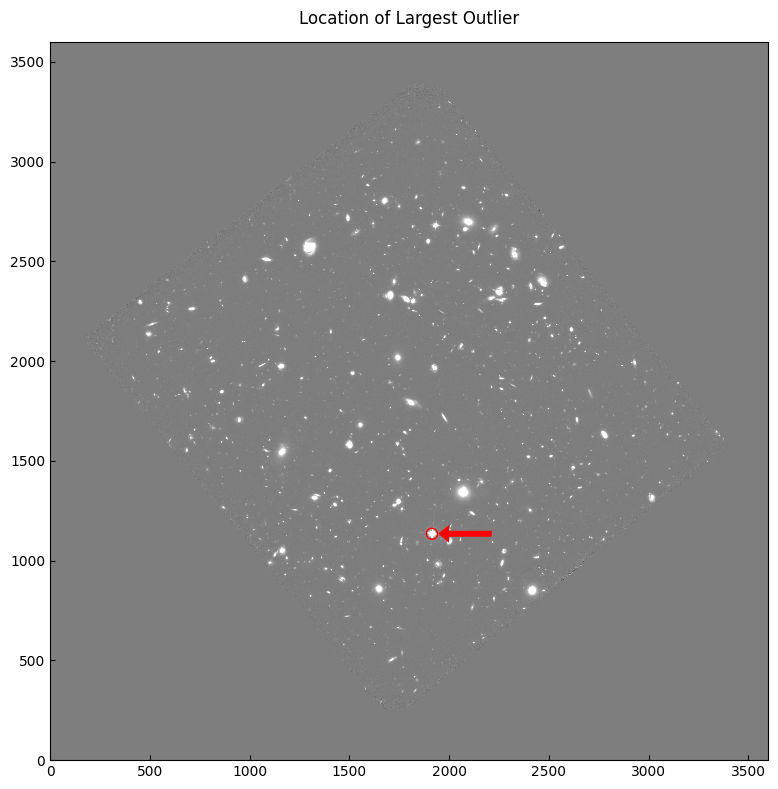

In [39]:
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
im = ax.imshow(data_sub, interpolation='nearest', cmap='gray',
               vmin=m-s, vmax=m+s, origin='lower')

ind=f105_largest_outlier_index
e = Ellipse(xy=(objects['x'][ind],objects['y'][ind]),
                width=10*objects['a'][ind],
                height=10*objects['b'][ind],
                angle=objects['theta'][ind] * 180. / np.pi)
e.set_facecolor('none')
e.set_edgecolor('red')
ax.add_artist(e)

arr_x = 300
arr_y = 0
_ = ax.add_artist(Arrow(x=objects['x'][ind]+arr_x,
                        y=objects['y'][ind]+arr_y,
                        dx=-arr_x+32,
                        dy=-arr_y,
                        fc='red',
                        width=150))

fig.suptitle('Location of Largest Outlier')
plt.tight_layout()

plt.show()

### RGB Image

Defines function to rescale the data as log base-10.  
Reads in each of the three data sets: f160, f125, f105. 
Subtracts each data's background from that data. 
Rescales the data sets into log base-10.  
Rescales the data linearly to be between 0.0 and 1.0.  
Stack the dataset as [y,x,3] to use as a false color image.

In [40]:
def rescale_image(data):
    pdata_tmp = data.copy()
    m = np.nanmean(pdata_tmp)
    vplmin = m/2.
    vpmin = np.log10(vplmin)
    vpmax = np.log10(m*100)
    pdata_tmp[pdata_tmp<vplmin] = vplmin
    pdata_tmp = np.log10(pdata_tmp)
    return pdata_tmp, vpmin, vpmax

In [41]:
data_fname1 = 'hlsp_hudf12_hst_wfc3ir_udfmain_f160w_v1.0_drz.fits'
data1 = fits.getdata(data_fname1)
data1 = np.astype(data1,np.float32)
data_fname2 = 'hlsp_hudf12_hst_wfc3ir_udfmain_f125w_v1.0_drz.fits'
data2 = fits.getdata(data_fname2)
data2 = np.astype(data2,np.float32)
data_fname3 = 'hlsp_hudf12_hst_wfc3ir_udfmain_f105w_v1.0_drz.fits'
data3 = fits.getdata(data_fname3)
data3 = np.astype(data3,np.float32)

data1 = data1 - sep.Background(data1)
data2 = data2 - sep.Background(data2)
data3 = data3 - sep.Background(data3)

data1,d1min,d1max = rescale_image(data1)
data1 = (data1-data1.min())/(data1.max()-data1.min())
data2,d2min,d2max = rescale_image(data2)
data2 = (data2-data2.min())/(data2.max()-data2.min())
data3,d3min,d3max = rescale_image(data3)
data3 = (data3-data3.min())/(data3.max()-data3.min())

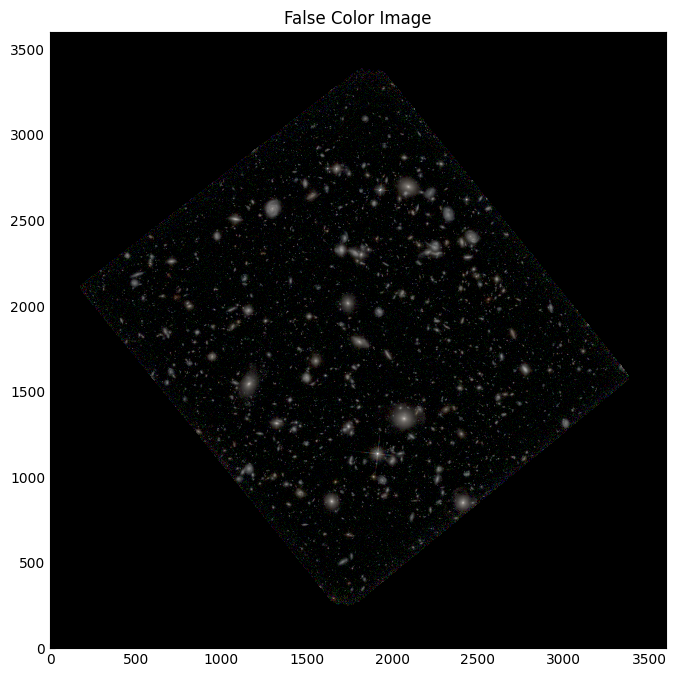

In [42]:
imdata = np.stack([data1,data2,data3],axis=-1)

fig,ax = plt.subplots(1,1)
ax.imshow(imdata, interpolation='nearest',origin='lower')
ax.set_title(f'False Color Image')

fig.savefig('Final_FalseColor.png',bbox_inches='tight',dpi = 600)
